# Stock Market Daily Trade Normalizer (ML_6)

**Experiment 1, 2 -- Data Preprocessing**

---

**Objective:** Process multi-stock historical datasets, engineer rolling window moving averages with NumPy, clean missing trade volumes, and plot comparative stock charts.

**Data:** Nifty 50 stocks, 5 years of daily OHLCV data (Oct 2021 - Oct 2026)

**Team:** Om Bijwani (24ESKCY036) + Partner (B240296)

---

## Table of Contents

1. [Setup & Configuration](#1-setup--configuration)
2. [Data Loading & Exploration](#2-data-loading--exploration)
3. [Data Cleaning](#3-data-cleaning---missing-trade-volumes)
4. [Feature Engineering with NumPy](#4-feature-engineering---rolling-window-moving-averages-with-numpy)
5. [Data Normalization](#5-data-normalization)
6. [Comparative Stock Charts](#6-comparative-stock-charts)
7. [Correlation Analysis](#7-correlation-analysis)
8. [Conclusion](#8-conclusion)

---
## 1. Setup & Configuration

In [2]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

# Add project root to path
project_root = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, project_root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import plotly.express as px
    import plotly.graph_objects as go
    PLOTLY_AVAILABLE = True
except ImportError:
    PLOTLY_AVAILABLE = False

from src import config
from src.feature_engineer import (
    compute_sma, compute_ema, compute_wma,
    compute_rolling_std, compute_daily_returns, compute_cumulative_returns
)
from src.normalizer import minmax_normalize, zscore_normalize
from src.utils import load_dataframe, list_csv_files, get_ticker_from_filename

# Plotting settings
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 100
sns.set_style('darkgrid')

print(f'Project: {config.PROJECT_NAME} ({config.PROJECT_ID})')
print(f'NumPy version: {np.__version__}')
print(f'Pandas version: {pd.__version__}')
print(f'Data range: {config.START_DATE} to {config.END_DATE}')

Project: Stock Market Daily Trade Normalizer (ML_6)
NumPy version: 2.5.3
Pandas version: 3.0.6
Data range: 2021-10-01 to 2026-10-01


In [3]:
# Load ticker list
tickers_df = pd.read_csv(config.TICKER_LIST_PATH)
print(f'Total tickers: {len(tickers_df)}')
print(f'\nSector distribution:')
print(tickers_df['Sector'].value_counts().to_string())
tickers_df.head(10)

Total tickers: 50

Sector distribution:
Sector
Financial Services    11
IT                     6
Automobile             6
Energy                 5
FMCG                   5
Healthcare             5
Metals                 4
Construction           3
Consumer Durables      2
Telecom                1
Diversified            1
Infrastructure         1


,Symbol,Company,Sector
0,RELIANCE.NS,Reliance Industries,Energy
1,TCS.NS,Tata Consultancy Services,IT
2,HDFCBANK.NS,HDFC Bank,Financial Services
3,INFY.NS,Infosys,IT
4,ICICIBANK.NS,ICICI Bank,Financial Services
5,HINDUNILVR.NS,Hindustan Unilever,FMCG
6,SBIN.NS,State Bank of India,Financial Services
7,BHARTIARTL.NS,Bharti Airtel,Telecom
8,ITC.NS,ITC Limited,FMCG
9,KOTAKBANK.NS,Kotak Mahindra Bank,Financial Services


---
## 2. Data Loading & Exploration

We have downloaded daily OHLCV (Open, High, Low, Close, Volume) data for Nifty 50 stocks.
Let's explore the raw data.

In [4]:
# Count available data files
raw_files = list_csv_files(config.RAW_DATA_DIR)
cleaned_files = list_csv_files(config.CLEANED_DATA_DIR)
processed_files = list_csv_files(config.PROCESSED_DATA_DIR)

print(f'Raw data files:       {len(raw_files)}')
print(f'Cleaned data files:   {len(cleaned_files)}')
print(f'Processed data files: {len(processed_files)}')

Raw data files:       48
Cleaned data files:   48
Processed data files: 48


In [5]:
# Load a sample raw stock to explore
sample_ticker = 'RELIANCE.NS'
sample_raw = load_dataframe(os.path.join(config.RAW_DATA_DIR, f'{sample_ticker}.csv'))

print(f'--- {sample_ticker} Raw Data ---')
print(f'Shape: {sample_raw.shape}')
print(f'Date range: {sample_raw.index.min()} to {sample_raw.index.max()}')
print(f'\nColumns: {list(sample_raw.columns)}')
print(f'\nMissing values:')
print(sample_raw.isnull().sum())
print(f'\nBasic statistics:')
sample_raw.describe().round(2)

--- RELIANCE.NS Raw Data ---
Shape: (1236, 6)
Date range: 2021-10-01 00:00:00 to 2026-09-30 00:00:00

Columns: ['Close', 'High', 'Low', 'Open', 'Volume', 'Adj Close']

Missing values:
Close        0
High         0
Low          0
Open         0
Volume       0
Adj Close    0
dtype: int64

Basic statistics:


,Close,High,Low,Open,Volume,Adj Close
count,1236.00,1236.00,1236.00,1236.00,1236.00,1236.00
mean,1274.50,1286.43,1263.43,1275.10,13270436.36,1274.50
std,142.70,143.35,142.17,142.71,6765399.22,142.70
min,1000.24,1008.76,987.36,1001.63,0.00,1000.24
25%,1156.26,1165.13,1146.07,1156.24,8831264.00,1156.26
50%,1256.06,1269.02,1242.61,1255.00,11728114.50,1256.06
75%,1401.81,1414.47,1388.76,1403.03,15943509.00,1401.81
max,1584.97,1604.38,1570.94,1585.67,81997149.00,1584.97


In [6]:
# Show the first few rows
sample_raw.head(10)

,Close,High,Low,Open,Volume,Adj Close
Date,,,,,,
2021-10-01,1143.028931,1150.320937,1130.030236,1133.177989,8958928,1143.028931
2021-10-04,1157.726074,1166.195597,1149.075293,1156.299372,10918552,1157.726074
2021-10-05,1181.753418,1183.021624,1153.740388,1157.250538,13533634,1181.753418
2021-10-06,1159.401978,1186.622290,1155.438983,1186.622290,10258881,1159.401978
2021-10-07,1165.086060,1177.020448,1162.957328,1175.321919,6336665,1165.086060
2021-10-08,1209.857056,1215.812929,1169.207606,1170.906015,15772493,1209.857056
2021-10-11,1201.432617,1231.936654,1198.126368,1223.512415,14768666,1201.432617
2021-10-12,1208.294312,1215.178757,1196.269354,1197.967883,6682011,1208.294312
2021-10-13,1220.590942,1231.710088,1208.973547,1213.366864,9959762,1220.590942


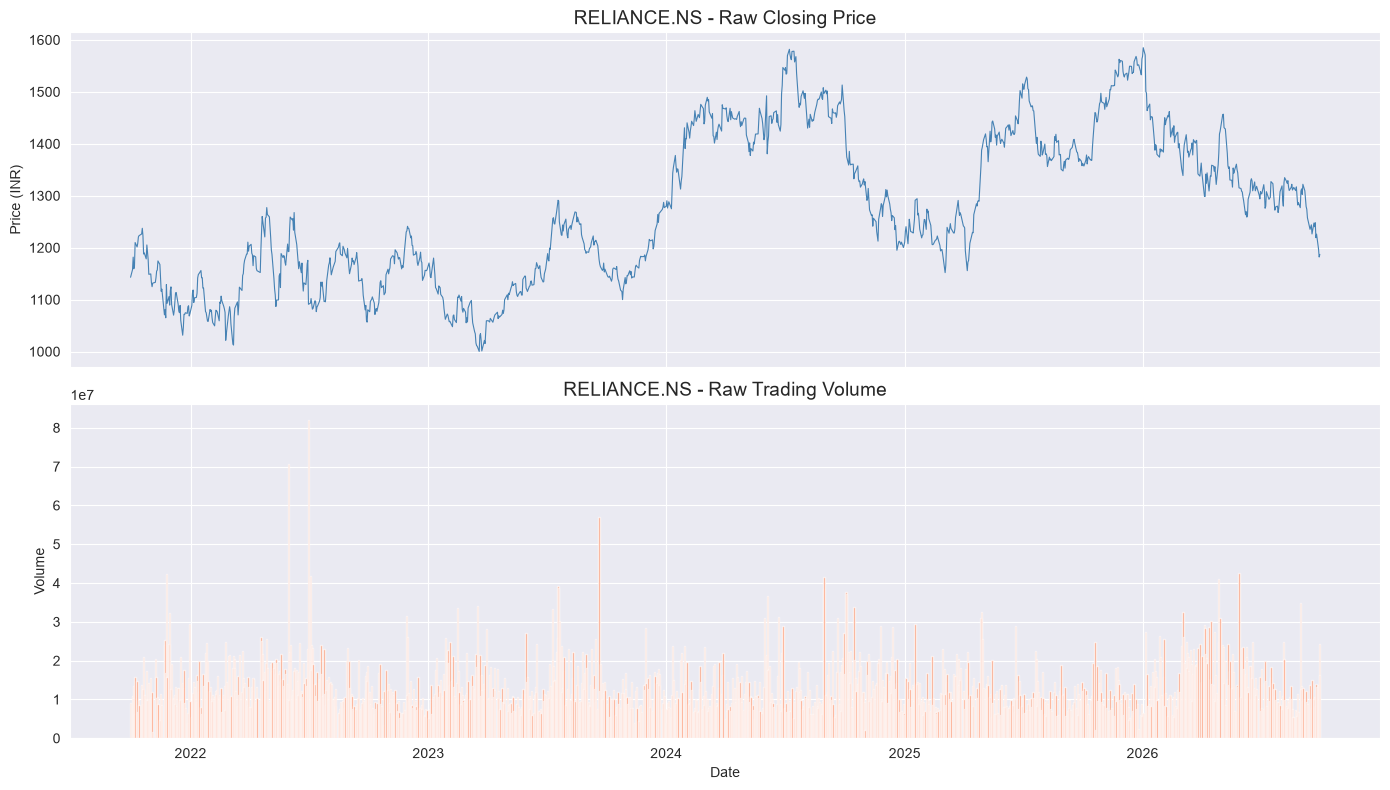

In [7]:
# Quick plot of raw closing price
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(sample_raw.index, sample_raw['Close'], color='steelblue', linewidth=0.8)
axes[0].set_title(f'{sample_ticker} - Raw Closing Price', fontsize=14)
axes[0].set_ylabel('Price (INR)')

axes[1].bar(sample_raw.index, sample_raw['Volume'], color='coral', alpha=0.7, width=2)
axes[1].set_title(f'{sample_ticker} - Raw Trading Volume', fontsize=14)
axes[1].set_ylabel('Volume')
axes[1].set_xlabel('Date')

plt.tight_layout()
plt.show()

In [8]:
# Missing data overview across ALL stocks (raw data)
missing_summary = []
for f in raw_files:
    ticker = get_ticker_from_filename(f)
    df = load_dataframe(f)
    missing_summary.append({
        'Ticker': ticker,
        'Rows': len(df),
        'Missing_Close': df['Close'].isnull().sum(),
        'Missing_Volume': df['Volume'].isnull().sum(),
        'Zero_Volume': (df['Volume'] == 0).sum() if 'Volume' in df.columns else 0
    })

missing_df = pd.DataFrame(missing_summary)
print('Missing/Zero data summary across all stocks:')
print(f'  Stocks with missing Close:  {(missing_df["Missing_Close"] > 0).sum()}')
print(f'  Stocks with missing Volume: {(missing_df["Missing_Volume"] > 0).sum()}')
print(f'  Stocks with zero Volume:    {(missing_df["Zero_Volume"] > 0).sum()}')
print(f'\nTotal missing Volume entries: {missing_df["Missing_Volume"].sum()}')
print(f'Total zero Volume entries:    {missing_df["Zero_Volume"].sum()}')

# Show stocks with issues
issues = missing_df[(missing_df['Missing_Close'] > 0) | (missing_df['Missing_Volume'] > 0) | (missing_df['Zero_Volume'] > 0)]
if len(issues) > 0:
    print(f'\nStocks with data quality issues ({len(issues)}):')
    display(issues.sort_values('Missing_Volume', ascending=False))
else:
    print('\nNo data quality issues found in raw data.')

Missing/Zero data summary across all stocks:
  Stocks with missing Close:  0
  Stocks with missing Volume: 0
  Stocks with zero Volume:    48

Total missing Volume entries: 0
Total zero Volume entries:    104

Stocks with data quality issues (48):


,Ticker,Rows,Missing_Close,Missing_Volume,Zero_Volume
0,ADANIENT.NS,1236,0,0,2
1,ADANIPORTS.NS,1236,0,0,2
2,APOLLOHOSP.NS,1236,0,0,2
3,ASIANPAINT.NS,1236,0,0,2
4,AXISBANK.NS,1236,0,0,2
5,BAJAJ-AUTO.NS,1236,0,0,3
6,BAJAJFINSV.NS,1236,0,0,2
7,BAJFINANCE.NS,1236,0,0,2
8,BHARTIARTL.NS,1236,0,0,2
9,BPCL.NS,1236,0,0,2


---
## 3. Data Cleaning - Missing Trade Volumes

Our cleaning strategy:
1. **Zero volumes** -> replaced with NaN (treated as missing)
2. **Missing Volume**: forward-fill -> backward-fill -> median fill
3. **Missing OHLC prices**: linear interpolation for gaps <= 5 days
4. **Outlier detection**: flag daily returns > 3 standard deviations

In [9]:
# Load the cleaning report
cleaning_report = pd.read_csv(os.path.join(config.REPORTS_DIR, 'cleaning_report.csv'))
print(f'Cleaning Report Summary ({len(cleaning_report)} stocks):')
print(f'  Total rows before cleaning: {cleaning_report["Original_Rows"].sum():,}')
print(f'  Total rows after cleaning:  {cleaning_report["Cleaned_Rows"].sum():,}')
print(f'  Total missing Volume (before): {cleaning_report["Missing_Before_Volume"].sum()}')
print(f'  Total missing Volume (after):  {cleaning_report["Missing_After_Volume"].sum()}')
print(f'  Total outliers flagged:        {cleaning_report["Outliers_Flagged"].sum()}')

cleaning_report.head(10)

Cleaning Report Summary (48 stocks):
  Total rows before cleaning: 59,328
  Total rows after cleaning:  59,328
  Total missing Volume (before): 104
  Total missing Volume (after):  0
  Total outliers flagged:        736


,Ticker,Original_Rows,Cleaned_Rows,Missing_Before_Volume,Missing_After_Volume,Missing_Before_Close,Missing_After_Close,Outliers_Flagged
0,ADANIENT.NS,1236,1236,2,0,0,0,21
1,ADANIPORTS.NS,1236,1236,2,0,0,0,19
2,APOLLOHOSP.NS,1236,1236,2,0,0,0,18
3,ASIANPAINT.NS,1236,1236,2,0,0,0,19
4,AXISBANK.NS,1236,1236,2,0,0,0,17
5,BAJAJ-AUTO.NS,1236,1236,3,0,0,0,15
6,BAJAJFINSV.NS,1236,1236,2,0,0,0,20
7,BAJFINANCE.NS,1236,1236,2,0,0,0,20
8,BHARTIARTL.NS,1236,1236,2,0,0,0,14
9,BPCL.NS,1236,1236,2,0,0,0,17


In [ ]:
# Before vs After cleaning comparison for a sample stock
sample_raw = load_dataframe(os.path.join(config.RAW_DATA_DIR, f'{sample_ticker}.csv'))
sample_cleaned = load_dataframe(os.path.join(config.CLEANED_DATA_DIR, f'{sample_ticker}.csv'))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(sample_raw.index, sample_raw['Volume'], color='red', alpha=0.6, linewidth=0.5)
axes[0].set_title(f'{sample_ticker} Volume - BEFORE Cleaning', fontsize=13)
axes[0].set_ylabel('Volume')
axes[0].set_xlabel('Date')

axes[1].plot(sample_cleaned.index, sample_cleaned['Volume'], color='green', alpha=0.6, linewidth=0.5)
axes[1].set_title(f'{sample_ticker} Volume - AFTER Cleaning', fontsize=13)
axes[1].set_ylabel('Volume')
axes[1].set_xlabel('Date')

plt.tight_layout()
plt.show()

print(f'Raw: {sample_raw["Volume"].isnull().sum()} missing, {(sample_raw["Volume"]==0).sum()} zeros')
print(f'Cleaned: {sample_cleaned["Volume"].isnull().sum()} missing, {(sample_cleaned["Volume"]==0).sum()} zeros')

---
## 4. Feature Engineering - Rolling Window Moving Averages with NumPy

All rolling window computations use **pure NumPy** (no pandas `.rolling()`).

### Moving Average Types:

1. **SMA (Simple Moving Average)**: $SMA_t = \frac{1}{w} \sum_{i=0}^{w-1} P_{t-i}$ -- implemented with `np.convolve`

2. **EMA (Exponential Moving Average)**: $EMA_t = \alpha \cdot P_t + (1-\alpha) \cdot EMA_{t-1}$ where $\alpha = \frac{2}{w+1}$ -- implemented with iterative loop

3. **WMA (Weighted Moving Average)**: $WMA_t = \frac{\sum_{i=0}^{w-1} (w-i) \cdot P_{t-i}}{\sum_{i=1}^{w} i}$ -- implemented with `np.dot`

In [ ]:
# Demonstrate moving averages on a sample stock
close_data = sample_cleaned['Close'].values
dates = sample_cleaned.index

# Compute SMAs with NumPy
sma_7 = compute_sma(close_data, 7)
sma_21 = compute_sma(close_data, 21)
sma_50 = compute_sma(close_data, 50)
sma_200 = compute_sma(close_data, 200)

print(f'Input array shape: {close_data.shape}')
print(f'SMA_7 shape:  {sma_7.shape}  | Non-NaN values: {np.count_nonzero(~np.isnan(sma_7))}')
print(f'SMA_21 shape: {sma_21.shape} | Non-NaN values: {np.count_nonzero(~np.isnan(sma_21))}')
print(f'SMA_50 shape: {sma_50.shape} | Non-NaN values: {np.count_nonzero(~np.isnan(sma_50))}')
print(f'SMA_200 shape: {sma_200.shape} | Non-NaN values: {np.count_nonzero(~np.isnan(sma_200))}')

In [ ]:
# Plot Close with SMA overlays
fig, ax = plt.subplots(figsize=(16, 8))

ax.plot(dates, close_data, label='Close', color='black', linewidth=0.8, alpha=0.7)
ax.plot(dates, sma_7, label='SMA(7)', color='#2196F3', linewidth=1)
ax.plot(dates, sma_21, label='SMA(21)', color='#FF9800', linewidth=1)
ax.plot(dates, sma_50, label='SMA(50)', color='#4CAF50', linewidth=1.2)
ax.plot(dates, sma_200, label='SMA(200)', color='#F44336', linewidth=1.5)

ax.set_title(f'{sample_ticker} - Close Price with Simple Moving Averages (NumPy)', fontsize=15)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Price (INR)', fontsize=12)
ax.legend(fontsize=11, loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Compare SMA vs EMA vs WMA for window=21
sma_21 = compute_sma(close_data, 21)
ema_21 = compute_ema(close_data, 21)
wma_21 = compute_wma(close_data, 21)

fig, ax = plt.subplots(figsize=(16, 7))

# Show last 250 days for clarity
n = 250
ax.plot(dates[-n:], close_data[-n:], label='Close', color='black', linewidth=0.8, alpha=0.5)
ax.plot(dates[-n:], sma_21[-n:], label='SMA(21)', color='#2196F3', linewidth=1.5)
ax.plot(dates[-n:], ema_21[-n:], label='EMA(21)', color='#FF9800', linewidth=1.5)
ax.plot(dates[-n:], wma_21[-n:], label='WMA(21)', color='#4CAF50', linewidth=1.5)

ax.set_title(f'{sample_ticker} - SMA vs EMA vs WMA (window=21, last {n} days)', fontsize=15)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Price (INR)', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print('Note: EMA responds faster to recent price changes (gives more weight to recent data).')
print('WMA also gives more weight to recent data, but linearly rather than exponentially.')

In [ ]:
# Rolling Volatility and Daily Returns
daily_returns = compute_daily_returns(close_data)
rolling_vol = compute_rolling_std(close_data, 21)
cumulative_ret = compute_cumulative_returns(daily_returns)

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

# Daily Returns
axes[0].bar(dates, daily_returns, color=np.where(daily_returns >= 0, 'green', 'red'), alpha=0.7, width=2)
axes[0].set_title(f'{sample_ticker} - Daily Returns', fontsize=14)
axes[0].set_ylabel('Return')
axes[0].axhline(y=0, color='black', linewidth=0.5)

# Rolling Volatility
axes[1].plot(dates, rolling_vol, color='purple', linewidth=0.8)
axes[1].fill_between(dates, 0, rolling_vol, alpha=0.2, color='purple')
axes[1].set_title(f'{sample_ticker} - 21-Day Rolling Volatility', fontsize=14)
axes[1].set_ylabel('Std Dev')

# Cumulative Returns
axes[2].plot(dates, cumulative_ret, color='darkorange', linewidth=1)
axes[2].set_title(f'{sample_ticker} - Cumulative Returns', fontsize=14)
axes[2].set_ylabel('Cumulative Return')
axes[2].set_xlabel('Date')
axes[2].axhline(y=1, color='black', linewidth=0.5, linestyle='--')

plt.tight_layout()
plt.show()

In [ ]:
# Load a processed stock to see all engineered features
sample_processed = load_dataframe(os.path.join(config.PROCESSED_DATA_DIR, f'{sample_ticker}.csv'))
print(f'Processed {sample_ticker} - {sample_processed.shape[0]} rows x {sample_processed.shape[1]} columns')
print(f'\nAll columns ({len(sample_processed.columns)}):')
for i, col in enumerate(sample_processed.columns, 1):
    print(f'  {i:2d}. {col}')

print(f'\nSample of engineered features (last 5 rows):')
feature_cols = [c for c in sample_processed.columns if 'SMA' in c or 'EMA' in c or 'WMA' in c or 'Return' in c or 'Volatility' in c]
sample_processed[feature_cols].tail(5).round(2)

---
## 5. Data Normalization

We normalize stock prices and volumes for fair cross-stock comparison:

- **Min-Max Normalization**: $X_{norm} = \frac{X - X_{min}}{X_{max} - X_{min}}$ (scales to [0, 1])
- **Z-Score Standardization**: $X_{std} = \frac{X - \mu}{\sigma}$ (mean=0, std=1)

In [ ]:
# Demonstrate normalization on sample stock
close = sample_cleaned['Close'].values

# Min-Max
norm_minmax, params_mm = minmax_normalize(close)
# Z-Score  
norm_zscore, params_zs = zscore_normalize(close)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(dates, close, color='steelblue')
axes[0].set_title('Original Close Price', fontsize=13)
axes[0].set_ylabel('Price (INR)')

axes[1].plot(dates, norm_minmax, color='green')
axes[1].set_title('Min-Max Normalized [0, 1]', fontsize=13)
axes[1].set_ylabel('Normalized Value')

axes[2].plot(dates, norm_zscore, color='orange')
axes[2].set_title('Z-Score Standardized', fontsize=13)
axes[2].set_ylabel('Z-Score')
axes[2].axhline(y=0, color='black', linewidth=0.5, linestyle='--')

for ax in axes:
    ax.set_xlabel('Date')

plt.suptitle(f'{sample_ticker} - Normalization Comparison', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

print(f'Min-Max params: min={params_mm["data_min"]:.2f}, max={params_mm["data_max"]:.2f}')
print(f'Z-Score params: mean={params_zs["mean"]:.2f}, std={params_zs["std"]:.2f}')

In [ ]:
# Normalization parameters report
norm_params = pd.read_csv(os.path.join(config.REPORTS_DIR, 'normalization_params.csv'))
print(f'Normalization parameters for {len(norm_params)} stock-column combinations:')
norm_params.head(10)

---
## 6. Comparative Stock Charts

Comparing multiple stocks requires normalization since stock prices have vastly different scales.

In [ ]:
# Load and normalize top stocks for comparison
# Pick stocks from different sectors
comparison_tickers = ['RELIANCE.NS', 'TCS.NS', 'HDFCBANK.NS', 'INFY.NS', 'ITC.NS',
                       'BHARTIARTL.NS', 'SBIN.NS', 'SUNPHARMA.NS', 'LT.NS', 'TITAN.NS']

# Load and normalize
fig, ax = plt.subplots(figsize=(16, 8))
for ticker in comparison_tickers:
    filepath = os.path.join(config.PROCESSED_DATA_DIR, f'{ticker}.csv')
    if os.path.exists(filepath):
        df = load_dataframe(filepath)
        close = df['Close'].values
        try:
            norm_close, _ = minmax_normalize(close)
            ax.plot(df.index, norm_close, label=ticker.replace('.NS', ''), linewidth=1)
        except ValueError:
            continue

ax.set_title('Comparative Normalized Stock Prices (Nifty 50 Selection)', fontsize=15)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Normalized Price [0, 1]', fontsize=12)
ax.legend(fontsize=10, ncol=2, loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Volume comparison across top stocks
avg_volumes = {}
for ticker in comparison_tickers:
    filepath = os.path.join(config.PROCESSED_DATA_DIR, f'{ticker}.csv')
    if os.path.exists(filepath):
        df = load_dataframe(filepath)
        avg_volumes[ticker.replace('.NS', '')] = df['Volume'].mean()

fig, ax = plt.subplots(figsize=(14, 6))
tickers_sorted = sorted(avg_volumes.keys(), key=lambda x: avg_volumes[x], reverse=True)
volumes_sorted = [avg_volumes[t] for t in tickers_sorted]

bars = ax.bar(tickers_sorted, volumes_sorted, color=plt.cm.tab10(np.linspace(0, 1, len(tickers_sorted))))
ax.set_title('Average Daily Trading Volume Comparison', fontsize=15)
ax.set_ylabel('Average Volume', fontsize=12)
ax.set_xlabel('Stock', fontsize=12)
ax.tick_params(axis='x', rotation=45)

# Add value labels
for bar, vol in zip(bars, volumes_sorted):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height(),
            f'{vol/1e6:.1f}M', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [ ]:
# Sector-wise average return comparison
sector_returns = []

for _, row in tickers_df.iterrows():
    ticker = row['Symbol']
    sector = row['Sector']
    filepath = os.path.join(config.PROCESSED_DATA_DIR, f'{ticker}.csv')
    if os.path.exists(filepath):
        df = load_dataframe(filepath)
        if 'Daily_Return' in df.columns:
            avg_return = df['Daily_Return'].mean()
            sector_returns.append({'Ticker': ticker, 'Sector': sector, 'Avg_Daily_Return': avg_return})

sector_df = pd.DataFrame(sector_returns)

fig, ax = plt.subplots(figsize=(14, 7))
sector_order = sector_df.groupby('Sector')['Avg_Daily_Return'].median().sort_values(ascending=False).index
sns.boxplot(data=sector_df, x='Sector', y='Avg_Daily_Return', order=sector_order, ax=ax, palette='Set2')
ax.set_title('Average Daily Returns by Sector', fontsize=15)
ax.set_xlabel('Sector', fontsize=12)
ax.set_ylabel('Average Daily Return', fontsize=12)
ax.tick_params(axis='x', rotation=45)
ax.axhline(y=0, color='black', linewidth=0.5, linestyle='--')

plt.tight_layout()
plt.show()

---
## 7. Correlation Analysis

In [ ]:
# Build daily returns matrix for correlation
returns_dict = {}
for f in processed_files:
    ticker = get_ticker_from_filename(f)
    df = load_dataframe(f)
    if 'Daily_Return' in df.columns:
        returns_dict[ticker.replace('.NS', '')] = df['Daily_Return']

returns_matrix = pd.DataFrame(returns_dict)
correlation = returns_matrix.corr()

# Plot correlation heatmap
fig, ax = plt.subplots(figsize=(18, 16))
mask = np.triu(np.ones_like(correlation, dtype=bool), k=1)
sns.heatmap(correlation, mask=mask, annot=False, cmap='RdYlGn', center=0,
            square=True, linewidths=0.5, ax=ax, vmin=-0.5, vmax=1,
            cbar_kws={'label': 'Correlation Coefficient'})
ax.set_title('Daily Return Correlation Heatmap - Nifty 50 Stocks', fontsize=16)

plt.tight_layout()
plt.show()

# Most and least correlated pairs
corr_pairs = correlation.where(mask).stack().reset_index()
corr_pairs.columns = ['Stock_1', 'Stock_2', 'Correlation']
corr_pairs = corr_pairs.sort_values('Correlation', ascending=False)

print('Top 5 most correlated pairs:')
for _, row in corr_pairs.head(5).iterrows():
    print(f'  {row["Stock_1"]:15s} <-> {row["Stock_2"]:15s}  r = {row["Correlation"]:.4f}')

print('\nTop 5 least correlated pairs:')
for _, row in corr_pairs.tail(5).iterrows():
    print(f'  {row["Stock_1"]:15s} <-> {row["Stock_2"]:15s}  r = {row["Correlation"]:.4f}')

In [ ]:
# Interactive chart (Plotly) - if available
if PLOTLY_AVAILABLE:
    fig = go.Figure()
    for ticker in comparison_tickers:
        filepath = os.path.join(config.PROCESSED_DATA_DIR, f'{ticker}.csv')
        if os.path.exists(filepath):
            df = load_dataframe(filepath)
            close = df['Close'].values
            try:
                norm_close, _ = minmax_normalize(close)
                fig.add_trace(go.Scatter(
                    x=df.index, y=norm_close,
                    name=ticker.replace('.NS', ''),
                    mode='lines'
                ))
            except ValueError:
                continue

    fig.update_layout(
        title='Interactive Comparative Stock Prices (Normalized)',
        xaxis_title='Date',
        yaxis_title='Normalized Price [0, 1]',
        hovermode='x unified',
        width=900, height=500
    )
    fig.show()
else:
    print('Plotly not available. Install with: pip install plotly')

---
## 8. Conclusion

### What we accomplished:

1. **Processed multi-stock historical datasets**: Downloaded and processed 5 years of daily OHLCV data for ~48 Nifty 50 stocks using yfinance.

2. **Engineered rolling window moving averages with NumPy**: Implemented SMA, EMA, and WMA using pure NumPy operations (`np.convolve`, iterative loops, `np.dot`) -- no pandas `.rolling()` used.

3. **Cleaned missing trade volumes**: Applied a multi-strategy approach (forward-fill, backward-fill, median fill) to handle missing and zero volume entries. Flagged outliers using 3-sigma detection.

4. **Plotted comparative stock charts**: Created both static (matplotlib) and interactive (Plotly) charts showing normalized price comparisons, volume analysis, sector returns, and correlation heatmaps.

### Key Observations:
- EMA responds faster to price changes than SMA (gives more weight to recent data)
- Stocks within the same sector tend to have higher return correlations
- Trading volumes vary significantly across stocks, making normalization essential for comparison
- The 200-day SMA serves as a key long-term trend indicator

### Pipeline Summary:
```
Raw Data (yfinance) -> Cleaning -> Feature Engineering -> Normalization -> Visualization
     48 stocks          48 CSVs      20+ features/stock     Min-Max/Z-Score    8 chart types
```

In [ ]:
# Final summary statistics
print('=' * 60)
print(f'  Project: {config.PROJECT_NAME} ({config.PROJECT_ID})')
print(f'  Stocks processed:    {len(processed_files)}')
print(f'  Date range:          {config.START_DATE} to {config.END_DATE}')
print(f'  Features engineered: {len(feature_cols)} per stock')
print(f'  Charts generated:    {len(os.listdir(config.CHARTS_DIR))} files')
print(f'  Reports generated:   {len(os.listdir(config.REPORTS_DIR))} files')
print('=' * 60)